Criação e vizualização dos grafos

In [1]:

import re
import csv

input_file = "ptwiki-20261101-pagelinks.sql"
output_file = "ptwiki_custom-20261101-edges.csv"

pattern = re.compile(rb'\((\d+),(\d+),(\d+)\)')

chunk_size = 16 * 1024 * 1024
carry = b""

with open(input_file, "rb") as infile, \
     open(output_file, "w", newline="") as outfile:

    writer = csv.writer(outfile)
    writer.writerow(["source_id", "source_namespace", "target_id"])

    while True:
        chunk = infile.read(chunk_size)

        if not chunk:
            break

        data = carry + chunk
        cutoff = max(0, len(data) - 128)
        last_end = 0

        for match in pattern.finditer(data):
            if match.end() > cutoff:
                break

            source, namespace, target = map(int, match.groups())

            if namespace == 0: #namespace 0 corresponde a outros artigos
                writer.writerow([source, namespace, target])

            last_end = match.end()

        carry = data[last_end:]

    # Process remaining data
    for match in pattern.finditer(carry):
        source, namespace, target = map(int, match.groups())

        if namespace == 0:
            writer.writerow([source, namespace, target])


Teste para ver se não houve algum erro na extração de dados

In [3]:
import csv

filename = "ptwiki_custom-20261101-edges.csv"

with open(filename, "r", newline="") as file:
    reader = csv.reader(file)

    header = next(reader)
    print("Header:", header)

    for i, row in enumerate(reader):
        if len(row) != 3:
            print("Invalid row:", i + 1, row)
            break
    else:
        print("All rows have exactly 3 columns.")
        print("\nTotal edges:", i + 1)

Header: ['source_id', 'source_namespace', 'target_id']
All rows have exactly 3 columns.

Total edges: 100366731


Parsear LinkTarget

In [12]:

import re
import csv

input_file = "ptwiki-20261101-linktarget.sql"
output_file = "ptwiki_custom-20261101-linktarget.csv"

# Match: (ID, namespace, 'title')
pattern = re.compile(
    rb"\((\d+),(-?\d+),'((?:\\.|''|[^'\\])*)'\)"
)


def mysql_unescape(value):
    """Decode MySQL/MariaDB string escape sequences."""

    result = bytearray()
    i = 0

    escapes = {
        ord('0'): 0,
        ord('b'): 8,
        ord('n'): 10,
        ord('r'): 13,
        ord('t'): 9,
        ord('Z'): 26,
        ord('\\'): ord('\\'),
        ord("'"): ord("'"),
        ord('"'): ord('"')
    }

    while i < len(value):

        if value[i] == ord('\\') and i + 1 < len(value):
            i += 1
            result.append(escapes.get(value[i], value[i]))

        elif value[i:i+2] == b"''":
            result.append(ord("'"))
            i += 1

        else:
            result.append(value[i])

        i += 1

    return bytes(result)


with open(input_file, "rb") as infile, \
     open(output_file, "w", newline="", encoding="utf-8") as outfile:

    writer = csv.writer(outfile)
    writer.writerow(["lt_id", "lt_namespace", "lt_title"])

    total_rows = 0
    extracted_rows = 0

    for line in infile:

        for match in pattern.finditer(line):

            lt_id = int(match.group(1))
            namespace = int(match.group(2))

            total_rows += 1

            if namespace != 0:
                continue

            title = mysql_unescape(match.group(3)).decode("utf-8")

            writer.writerow([lt_id, namespace, title])
            extracted_rows += 1

print("Total rows:", total_rows)
print("Namespace 0 targets:", extracted_rows)


Total rows: 11958427
Namespace 0 targets: 5774203


In [13]:
import csv
import re

input_file = "ptwiki_custom-20261101-linktarget.csv"

pattern = re.compile(r"\\[0btnrZ\\'\"]")

count = 0
examples = []

with open(input_file, "r", encoding="utf-8") as file:

    reader = csv.DictReader(file)

    for row in reader:

        title = row["lt_title"]

        if pattern.search(title):
            count += 1

            if len(examples) < 10:
                examples.append(title)

print("Potential remaining SQL escapes:", count)
print("Examples:", examples)

Potential remaining SQL escapes: 22
Examples: ['"C:\\Documents_and_Settings\\Administrador\\Meus_documentos\\Minhas_imagens\\topo.jpg"', "'+title+'\\n", "',_'').replace(u'\\n',_''_'::').replace('", 'Badza\\tiritose', 'Colégio_az_oi\\\\\\', 'Foo\\\'s_"bar"', 'Http:\\\\www.europarl.europa.eu/sides/getDoc.do?pubRef=-//EP//TEXT+IMPRESS+20081216IPR44857+0+DOC+XML+V0//PT_“O_Ambiente_na_Europa_–_situação_actual_e_perspectivas”_–_SOER_2010', 'Http\\\\:folhadobico.com.br', 'Https:\\\\willianwstermann.com.br', 'Https:\\\\www.westermannsa.com.br\\']


In [14]:
import csv

input_file = "ptwiki_custom-20261101-linktarget.csv"

with open(input_file, "r", encoding="utf-8") as file:
    reader = csv.DictReader(file)

    for row in reader:
        title = row["lt_title"]

        if "\\'" in title:
            print(repr(title))

'Foo\\\'s_"bar"'
"Nossa_Senhora_d\\\\\\'Ablon"
"\\',\\'"


In [15]:

import re

input_file = "ptwiki-20261101-linktarget.sql"

search_terms = [
    b"Foo",
    b"Nossa_Senhora_d",
]

with open(input_file, "rb") as file:

    for line in file:

        if any(term in line for term in search_terms):
            print(line.decode("utf-8", errors="replace"))


(3568449,0,'\"Igreja_de_Nossa_Senhora_do_Carmo_(Carmo)\"'),

(4805458,0,'\"Nossa_Senhora_das_Flores\"'),

(6075754,0,'\'\'Food_Network\'\''),

(3110286,0,'(Now_and_Then_There\'s)_A_Fool_Such_as_I'),

(2324442,0,'11x11:_Football_Manager'),

(749349,0,'12_de_Octubre_Football_Club'),

(7125187,0,'12th_Regiment_of_Foot'),

(1823257,0,'13_de_Julho_Football_Club'),

(11547872,0,'14th_Regiment_of_Foot'),

(11132873,0,'15_12_2011:es:Hospital_Nossa_Senhora_da_Paz_(Cubal,_Angola)'),

(12006842,0,'15_de_Agosto_Football_Club'),

(4148701,0,'15_de_Novembro_Foot-Ball_Club'),

(1102510,0,'1874_Northwich_Football_Club'),

(3646389,0,'1888-89_Football_League'),

(3646390,0,'1888–89_Football_League'),

(3646391,0,'1889-90_Football_League'),

(3646392,0,'1889–90_Football_Alliance'),

(3646393,0,'1889–90_Football_League'),

(11974720,0,'1890–91_Scottish_Football_League'),

(11974722,0,'1891–92_Scottish_Football_League'),

(11974723,0,'1892–93_Scottish_Football_League'),

(7047808,0,'1893–94_Football_Leagu

Parseando Page

In [9]:

import re
import csv

input_file = "ptwiki-20261101-page.sql"
output_file = "ptwiki_custom-20261101-pages.csv"

row_pattern = re.compile(
    r"\((\d+),(\d+),'((?:[^'\\]|\\.)*)',"
)

def decode_sql_string(value):
    """Decode MariaDB/MySQL backslash escapes."""

    replacements = {
        r"\0": "\0",
        r"\b": "\b",
        r"\t": "\t",
        r"\n": "\n",
        r"\r": "\r",
        r"\Z": "\x1a",
        r"\\": "\\",
        r"\'": "'",
        r'\"': '"'
    }

    pattern = re.compile(r"\\[0btnrZ\\'\"]")

    return pattern.sub(
        lambda match: replacements[match.group(0)],
        value
    )


total_rows = 0
main_namespace_rows = 0

with open(input_file, "r", encoding="utf-8") as infile, \
     open(output_file, "w", newline="", encoding="utf-8") as outfile:

    writer = csv.writer(outfile)

    writer.writerow([
        "page_id",
        "page_namespace",
        "page_title"
    ])

    for line in infile:

        if not line.startswith("("):
            continue

        for match in row_pattern.finditer(line):

            page_id = int(match.group(1))
            namespace = int(match.group(2))
            title = decode_sql_string(match.group(3))

            total_rows += 1

            if namespace == 0:

                writer.writerow([
                    page_id,
                    namespace,
                    title
                ])

                main_namespace_rows += 1


print("Total rows:", total_rows)
print("Main namespace pages:", main_namespace_rows)


Total rows: 6218324
Main namespace pages: 2021680


#Finalmente fazendo o grafo
1- Usando o Page identificar os source_id dde edges
2- Usando o linktarget para identificar os target_id
3- Usando o linktarget e Page para identificar os targets

In [16]:
#instalando o duckdb
%pip install duckdb

   ---------------------------------------- 0.0/15.4 MB ? eta -:--:--
    --------------------------------------- 0.3/15.4 MB ? eta -:--:--
   - -------------------------------------- 0.5/15.4 MB 2.0 MB/s eta 0:00:08
   -- ------------------------------------- 1.0/15.4 MB 2.1 MB/s eta 0:00:07
   ---- ----------------------------------- 1.6/15.4 MB 2.1 MB/s eta 0:00:07
   ----- ---------------------------------- 2.1/15.4 MB 2.1 MB/s eta 0:00:07
   ------ --------------------------------- 2.6/15.4 MB 2.1 MB/s eta 0:00:06
   -------- ------------------------------- 3.1/15.4 MB 2.2 MB/s eta 0:00:06
   --------- ------------------------------ 3.7/15.4 MB 2.2 MB/s eta 0:00:06
   ---------- ----------------------------- 4.2/15.4 MB 2.2 MB/s eta 0:00:05
   ----------- ---------------------------- 4.5/15.4 MB 2.2 MB/s eta 0:00:05
   ------------ --------------------------- 4.7/15.4 MB 2.2 MB/s eta 0:00:05
   ------------- -------------------------- 5.2/15.4 MB 2.1 MB/s eta 0:00:05
   ----------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:

import duckdb

# Input files
edges_file = "ptwiki_custom-20261101-edges.csv"
pages_file = "ptwiki_custom-20261101-pages.csv"
linktarget_file = "ptwiki_custom-20261101-linktarget.csv"

# Output files
output_edges = "ptwiki_custom-20261101-graph.parquet"
output_nodes = "ptwiki_custom-20261101-nodes.parquet"

# Create DuckDB connection
con = duckdb.connect()

# Join the three datasets and save the final directed edges
con.execute(f"""
    COPY (
        SELECT
            src.page_id AS source_id,
            dst.page_id AS target_id

        FROM read_csv_auto('{edges_file}', header=true) AS e

        INNER JOIN read_csv_auto('{pages_file}', header=true) AS src
            ON e.source_id = src.page_id

        INNER JOIN read_csv_auto('{linktarget_file}', header=true) AS lt
            ON e.target_id = lt.lt_id

        INNER JOIN read_csv_auto('{pages_file}', header=true) AS dst
            ON lt.lt_title = dst.page_title
            AND lt.lt_namespace = dst.page_namespace

    ) TO '{output_edges}'
    (FORMAT PARQUET, COMPRESSION ZSTD);
""")

# Save the article ID-to-title mapping
con.execute(f"""
    COPY (
        SELECT
            page_id,
            page_title

        FROM read_csv_auto('{pages_file}', header=true)

    ) TO '{output_nodes}'
    (FORMAT PARQUET, COMPRESSION ZSTD);
""")

# Consolidated result summary
edge_count = con.execute(f"""
    SELECT COUNT(*) FROM read_parquet('{output_edges}')
""").fetchone()[0]

node_count = con.execute(f"""
    SELECT COUNT(*) FROM read_parquet('{output_nodes}')
""").fetchone()[0]

print("Graph construction finished!")
print("Nodes:", f"{node_count:,}")
print("Edges:", f"{edge_count:,}")

con.close()


Graph construction finished!
Nodes: 2,021,680
Edges: 83,182,587


Agora vamos vizualizar o grafo de forma "global" e então buscar comunidades (se couber o tempo)

In [18]:
%pip install igraph matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/3.2 MB ? eta -:--:--
   --- ------------------------------------ 0.3/3.2 MB ? eta -:--:--
   ------ --------------------------------- 0.5/3.2 MB 1.4 MB/s eta 0:00:02
   --------- ------------------------------ 0.8/3.2 MB 1.3 MB/s eta 0:00:02
   --------- ------------------------------ 0.8/3.2 MB 1.3 MB/s eta 0:00:02
   ------------- -------------------------- 1.0/3.2 MB 938.7 kB/s eta 0:00:03
   ---------------- ----------------------- 1.3/3.2 MB 1.1 MB/s eta 0:00:02
   ---------------------- ----------------- 1.8/3.2 MB 1.3 MB/s eta 0:00:02
   -------------------------- ------------- 2.1/3.2 MB 1.3 MB/s eta 0:00:01
   -------------------------------- ------- 2.6/3.2 MB 1.4 MB/s eta 0:00:01
   ----------------------------------- ---- 2.9/3.2 MB 1.4 MB/s eta 0:00:01
   ---------------------------------------- 3.2/3.2 MB 1.4 MB/s  0:00:02
   ------------------------------------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Sampled nodes: 35641
Sampled edges: 20000


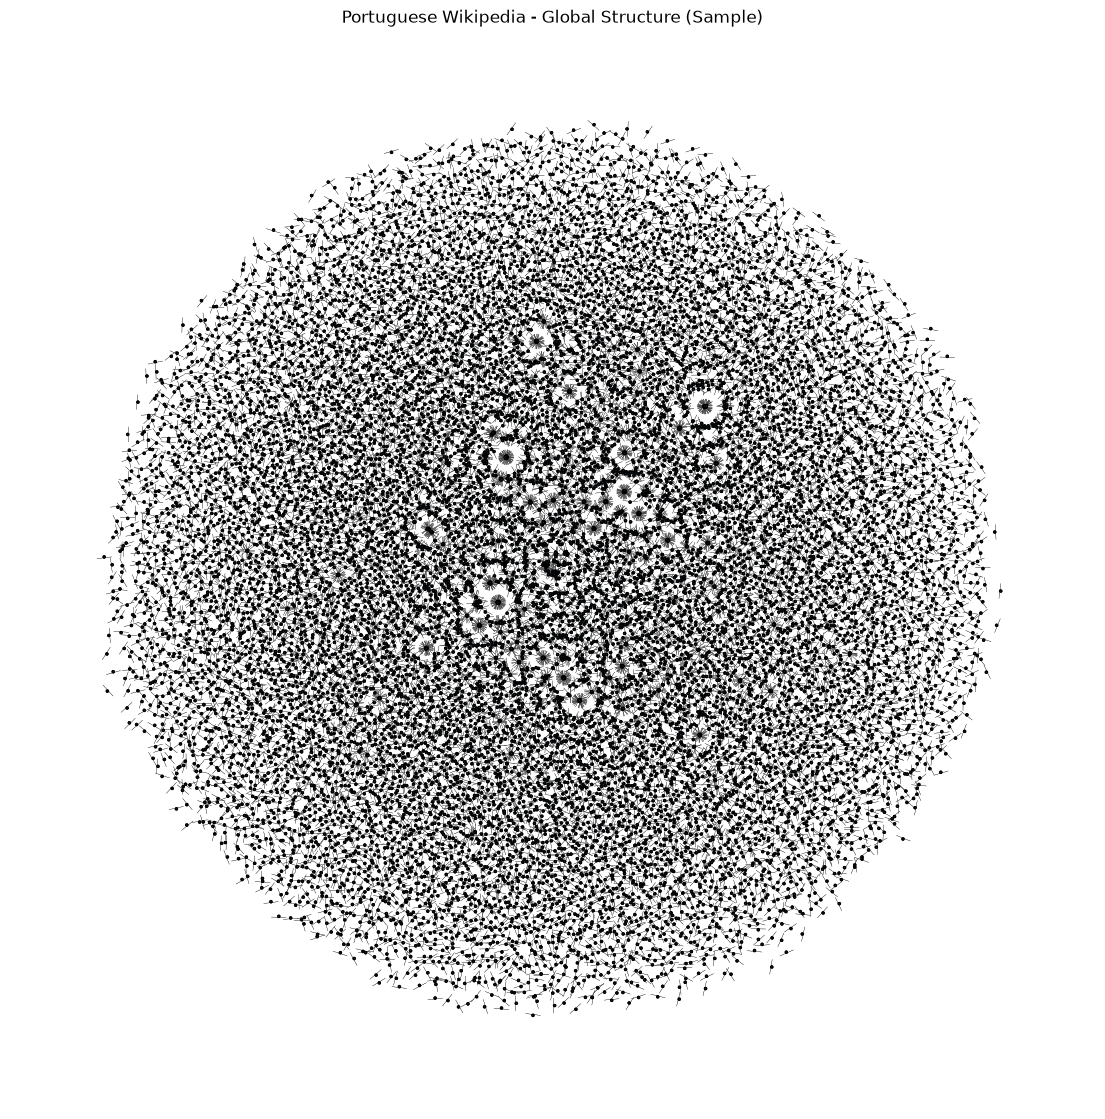

Communities found: 15642


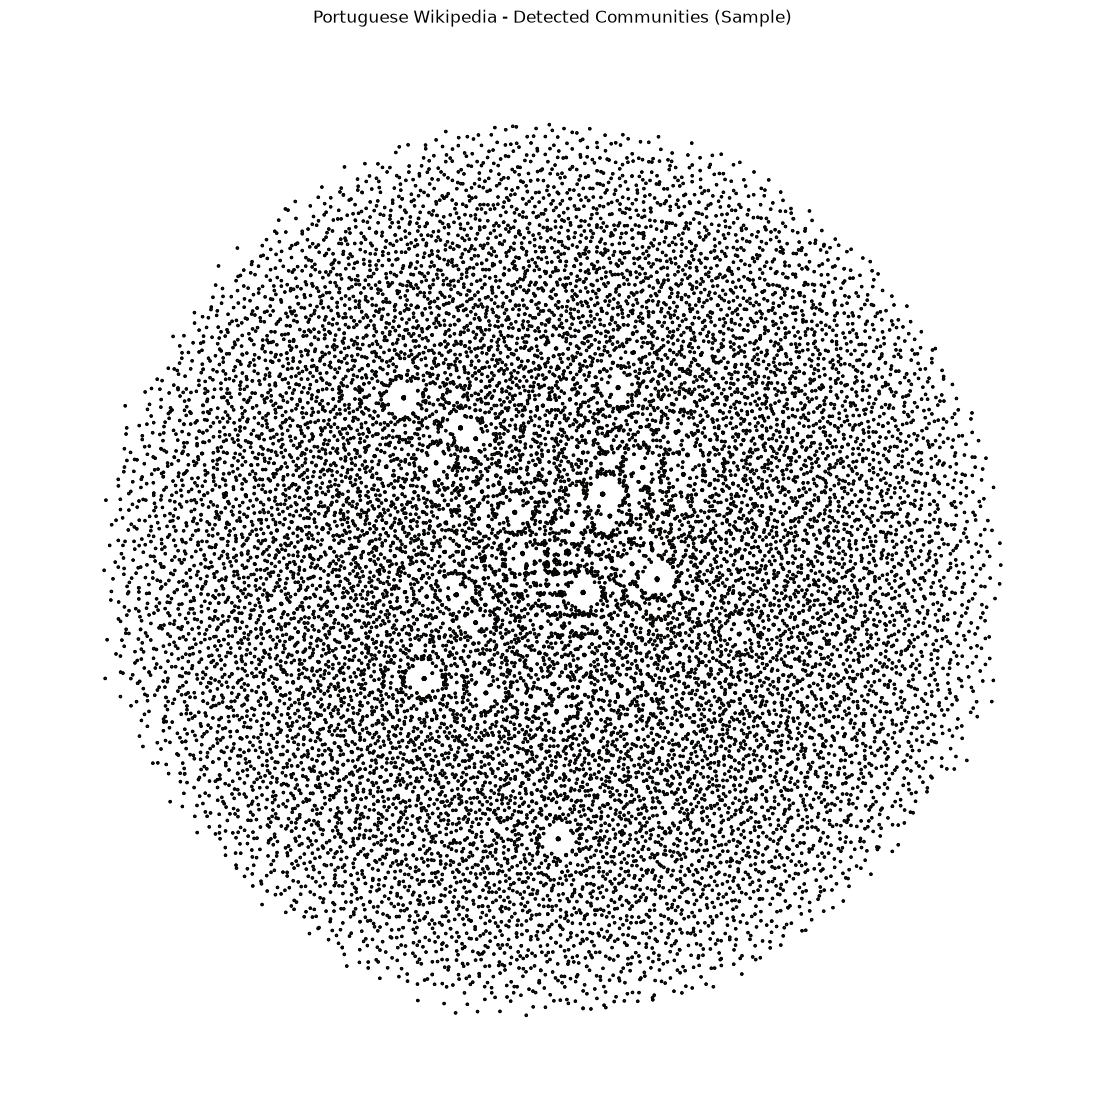

In [29]:
import duckdb
import igraph as ig
import matplotlib.pyplot as plt

# 1. Sample edges from the full graph
con = duckdb.connect()

edges = con.execute("""
    SELECT source_id, target_id
    FROM read_parquet('ptwiki_custom-20261101-graph.parquet')
    USING SAMPLE 20000 ROWS
""").fetchall()

con.close()

# 2. Convert original page IDs into compact vertex indices
page_ids = list(set(
    [source for source, target in edges] +
    [target for source, target in edges]
))

id_to_index = {page_id: i for i, page_id in enumerate(page_ids)}

sampled_edges = [
    (id_to_index[source], id_to_index[target])
    for source, target in edges
]

g = ig.Graph(
    n=len(page_ids),
    edges=sampled_edges,
    directed=True
)

print("Sampled nodes:", g.vcount())
print("Sampled edges:", g.ecount())

# 3. Global structure
layout = g.layout_drl()

fig, ax = plt.subplots(figsize=(14, 14))

ig.plot(
    g,
    target=ax,
    layout=layout,
    vertex_size=2,
    vertex_color="steelblue",
    vertex_label=None,
    edge_width=0.2,
    edge_arrow_size=0
)

ax.set_title("Portuguese Wikipedia - Global Structure (Sample)")
plt.show()

# 4. Community detection
undirected = g.as_undirected()
undirected.simplify(multiple=True, loops=True)

communities = undirected.community_leiden(
    objective_function="modularity",
    n_iterations=2
)

print("Communities found:", len(communities))

# 5. Color nodes according to their community
cmap = plt.get_cmap("turbo", len(communities))
community_colors = [
    cmap(membership)
    for membership in communities.membership
]

community_layout = undirected.layout_drl()

fig, ax = plt.subplots(figsize=(14, 14))

ig.plot(
    undirected,
    target=ax,
    layout=community_layout,
    vertex_size=2,
    vertex_color=community_colors,
    vertex_label=None,
    edge_width=0.2
)

ax.set_title("Portuguese Wikipedia - Detected Communities (Sample)")
plt.show()


44963 é Ciência de acordo com Linktarget

In [2]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Starting article: Ciência (ID: 554)

Most relevant neighbors:


[{'candidate_id': 1323,
  'page_title': 'Método_científico',
  'shared_neighbors': 575,
  'candidate_degree': 1471,
  'outgoing': 1,
  'incoming': 1,
  'weight': 0.13215352792461504},
 {'candidate_id': 265314,
  'page_title': 'História_da_ciência',
  'shared_neighbors': 429,
  'candidate_degree': 1052,
  'outgoing': 1,
  'incoming': 1,
  'weight': 0.10519862677783227},
 {'candidate_id': 23342,
  'page_title': 'Pseudociência',
  'shared_neighbors': 435,
  'candidate_degree': 1309,
  'outgoing': 1,
  'incoming': 1,
  'weight': 0.10048510048510048},
 {'candidate_id': 1809,
  'page_title': 'Tecnologia',
  'shared_neighbors': 538,
  'candidate_degree': 2813,
  'outgoing': 1,
  'incoming': 1,
  'weight': 0.09389179755671902},
 {'candidate_id': 75819,
  'page_title': 'Ciências_sociais',
  'shared_neighbors': 424,
  'candidate_degree': 1591,
  'outgoing': 1,
  'incoming': 1,
  'weight': 0.09173517957594116},
 {'candidate_id': 826,
  'page_title': 'Física',
  'shared_neighbors': 715,
  'candida

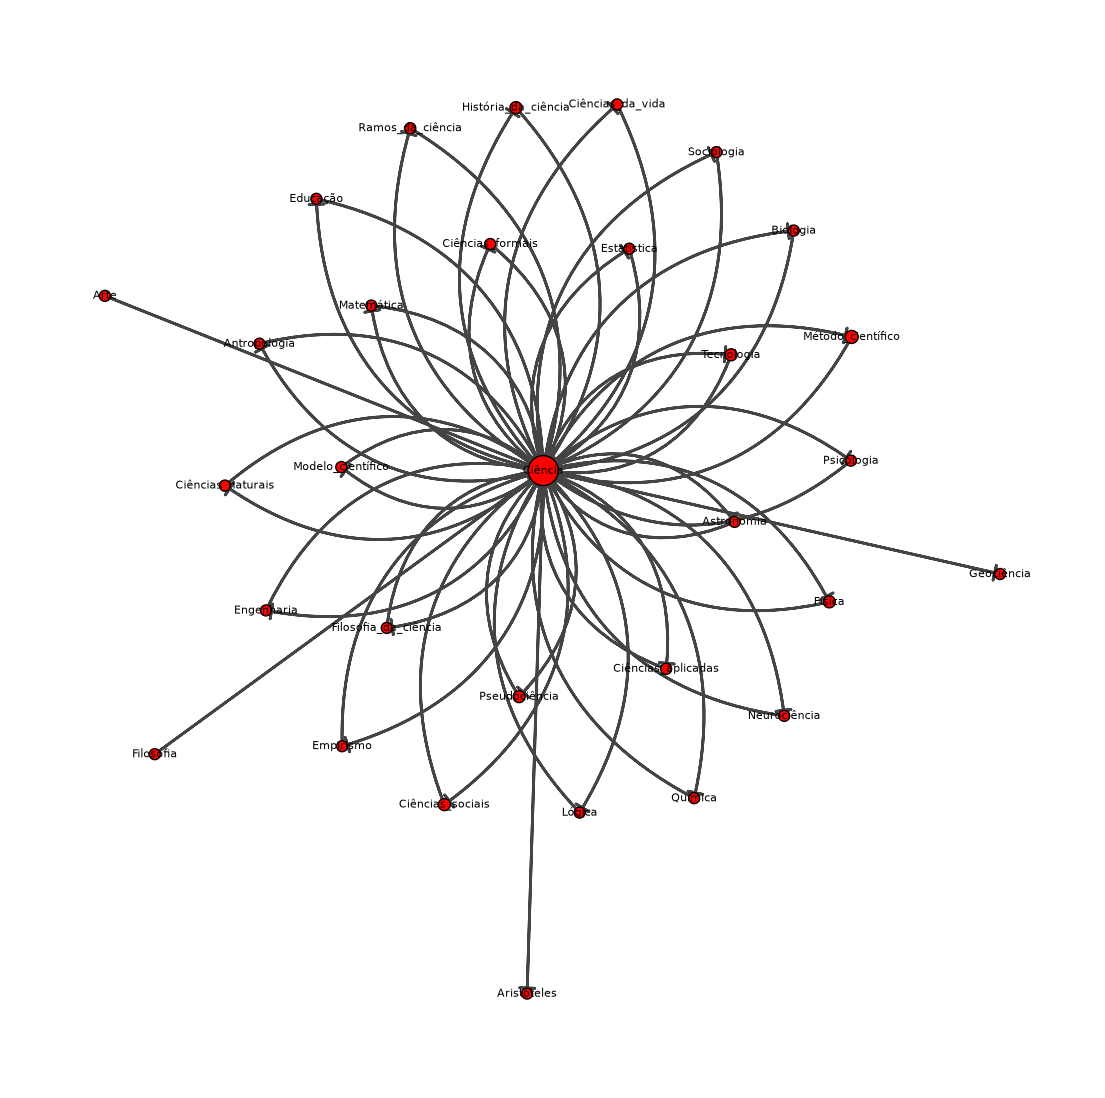

In [9]:
import duckdb
import igraph as ig
import matplotlib.pyplot as plt

# Files
graph_file = "ptwiki_custom-20261101-graph.parquet"
nodes_file = "ptwiki_custom-20261101-nodes.parquet"

# Settings
starting_article = "Ciência"
top_n = 30

con = duckdb.connect()

# Find the starting article
result = con.execute("""
    SELECT page_id, page_title
    FROM read_parquet(?)
    WHERE replace(page_title, '_', ' ') = ?
""", [nodes_file, starting_article]).fetchone()

if result is None:
    raise ValueError(f"Article not found: {starting_article}")

seed_id, seed_title = result

print(f"Starting article: {seed_title} (ID: {seed_id})")

# Find and rank its neighbors
query = """
WITH seed_neighbors AS (
    -- Articles linked FROM the starting article
    SELECT target_id AS candidate_id
    FROM read_parquet(?)
    WHERE source_id = ?

    UNION

    -- Articles linking TO the starting article
    SELECT source_id AS candidate_id
    FROM read_parquet(?)
    WHERE target_id = ?
),

seed_degree AS (
    SELECT COUNT(*) AS n
    FROM seed_neighbors
),

candidate_neighbors AS (
    -- Outgoing neighbors of each candidate
    SELECT e.source_id AS candidate_id, e.target_id AS neighbor_id
    FROM read_parquet(?) e
    INNER JOIN seed_neighbors s
        ON e.source_id = s.candidate_id

    UNION

    -- Incoming neighbors of each candidate
    SELECT e.target_id AS candidate_id, e.source_id AS neighbor_id
    FROM read_parquet(?) e
    INNER JOIN seed_neighbors s
        ON e.target_id = s.candidate_id
),

candidate_stats AS (
    SELECT
        candidate_id,
        COUNT(DISTINCT neighbor_id) AS candidate_degree,

        COUNT(DISTINCT CASE
            WHEN neighbor_id IN (
                SELECT candidate_id FROM seed_neighbors
            )
            THEN neighbor_id
        END) AS shared_neighbors

    FROM candidate_neighbors
    GROUP BY candidate_id
),

directed_links AS (
    SELECT
        target_id AS candidate_id,
        COUNT(*) AS outgoing,
        0 AS incoming
    FROM read_parquet(?)
    WHERE source_id = ?
    GROUP BY target_id

    UNION ALL

    SELECT
        source_id AS candidate_id,
        0 AS outgoing,
        COUNT(*) AS incoming
    FROM read_parquet(?)
    WHERE target_id = ?
    GROUP BY source_id
),

direction_counts AS (
    SELECT
        candidate_id,
        SUM(outgoing) AS outgoing,
        SUM(incoming) AS incoming
    FROM directed_links
    GROUP BY candidate_id
)

SELECT
    n.page_id AS candidate_id,
    n.page_title,

    s.shared_neighbors,
    s.candidate_degree,

    d.outgoing,
    d.incoming,

    s.shared_neighbors * 1.0 /
    NULLIF(
        (SELECT n FROM seed_degree)
        + s.candidate_degree
        - s.shared_neighbors,
        0
    ) AS weight

FROM candidate_stats s

JOIN read_parquet(?) n
    ON n.page_id = s.candidate_id

JOIN direction_counts d
    ON d.candidate_id = s.candidate_id

ORDER BY weight DESC, shared_neighbors DESC

LIMIT ?
"""

neighbor_result = con.execute(query, [
    graph_file, seed_id,
    graph_file, seed_id,
    graph_file,
    graph_file,
    graph_file, seed_id,
    graph_file, seed_id,
    nodes_file,
    top_n
])

neighbor_columns = [column[0] for column in neighbor_result.description]
neighbors = [
    dict(zip(neighbor_columns, row))
    for row in neighbor_result.fetchall()
]

print("\nMost relevant neighbors:")
display(neighbors)

# Build a small directed graph for visualization
g = ig.Graph(directed=True)

ids = [seed_id] + [row["candidate_id"] for row in neighbors]
titles = [seed_title] + [row["page_title"] for row in neighbors]

id_to_index = {article_id: i for i, article_id in enumerate(ids)}

g.add_vertices(len(ids))
g.vs["name"] = titles

edges = []

for row in neighbors:
    candidate_index = id_to_index[row["candidate_id"]]

    # Starting article -> candidate
    if row["outgoing"] > 0:
        edges.append((0, candidate_index))

    # Candidate -> starting article
    if row["incoming"] > 0:
        edges.append((candidate_index, 0))

g.add_edges(edges)

# Larger nodes indicate higher weights
sizes = [30] + [
    10 + 25 * float(row["weight"])
    for row in neighbors
]
fig, ax = plt.subplots(figsize=(14, 14))

ig.plot(
    g,
    target=ax,
    layout=g.layout("fr"),
    vertex_size=sizes,
    vertex_label=titles,
    vertex_label_size=8,
    edge_arrow_size=0.5,
    edge_arrow_alpha=0.1,
    margin=60
)

plt.show()

con.close()


agora com os vizinhos se referenciando

Starting article: Ciência (ID: 554)

Selected neighbors:
Método_científico: weight=0.1322, shared=575, outgoing=1, incoming=1
História_da_ciência: weight=0.1052, shared=429, outgoing=1, incoming=1
Pseudociência: weight=0.1005, shared=435, outgoing=1, incoming=1
Tecnologia: weight=0.0939, shared=538, outgoing=1, incoming=1
Ciências_sociais: weight=0.0917, shared=424, outgoing=1, incoming=1
Física: weight=0.0855, shared=715, outgoing=1, incoming=1
Ciências_formais: weight=0.0769, shared=269, outgoing=1, incoming=1
Matemática: weight=0.0709, shared=719, outgoing=1, incoming=1
Antropologia: weight=0.0703, shared=384, outgoing=1, incoming=1
Lógica: weight=0.0703, shared=333, outgoing=1, incoming=1
Química: weight=0.0699, shared=504, outgoing=1, incoming=1
Filosofia: weight=0.0698, shared=665, outgoing=0, incoming=1
Aristóteles: weight=0.0688, shared=426, outgoing=1, incoming=0
Empirismo: weight=0.0687, shared=327, outgoing=1, incoming=1
Ciências_naturais: weight=0.0677, shared=276, outgoing

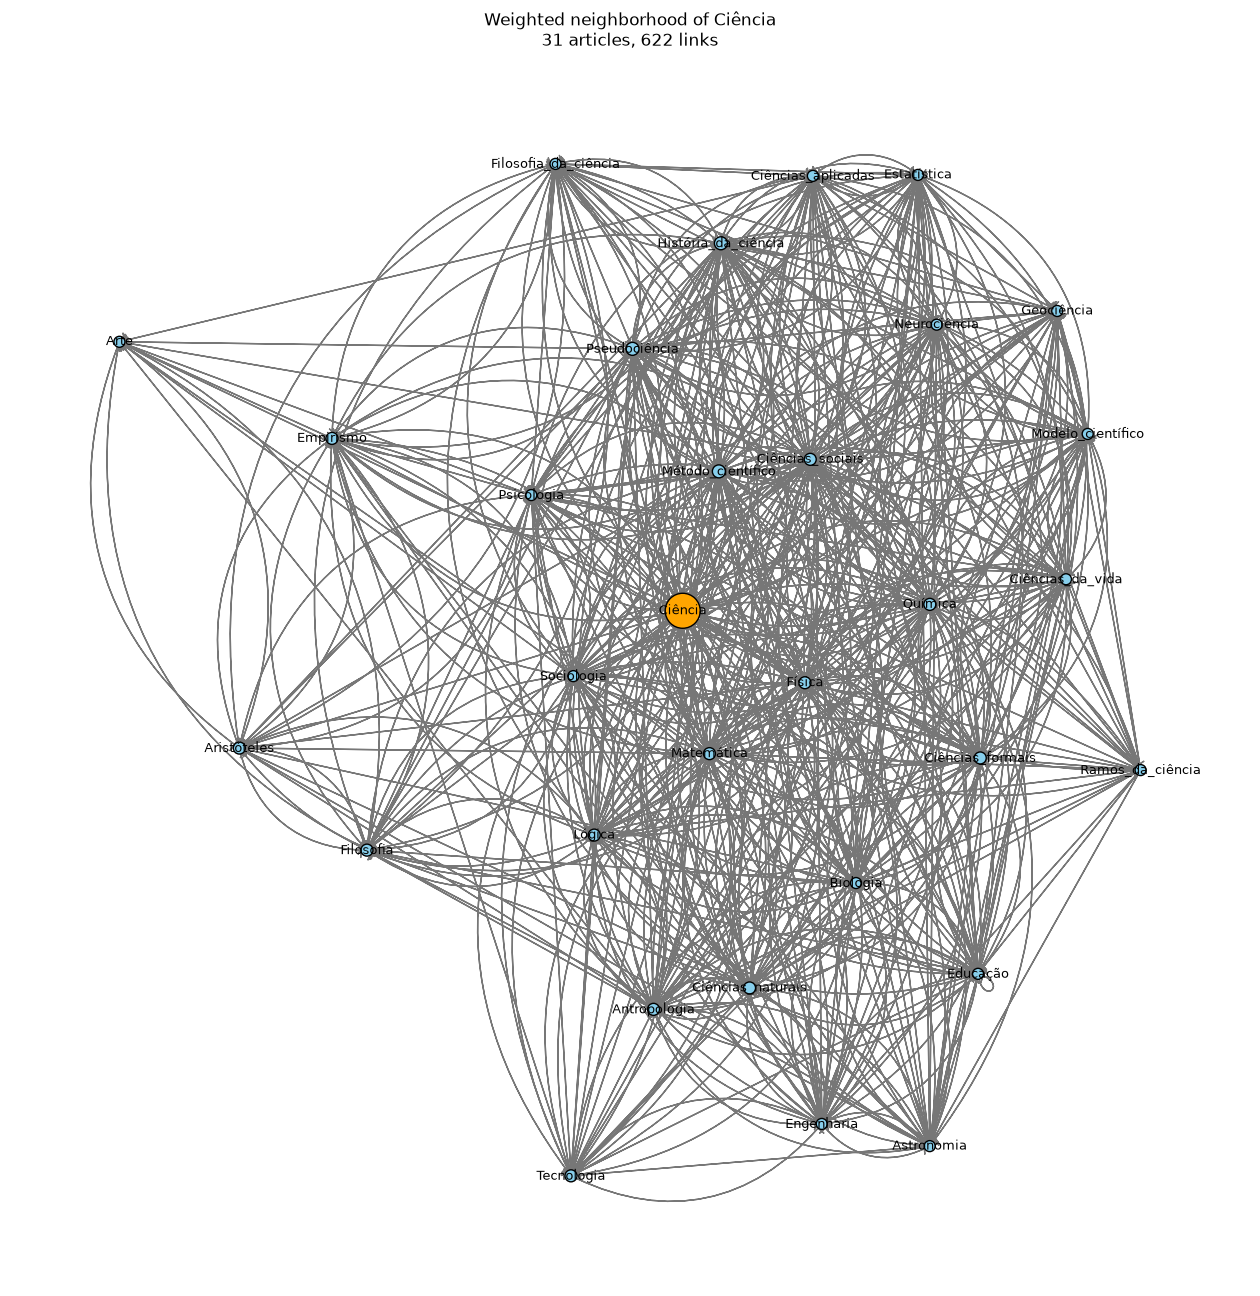


Articles: 31
Links between selected articles: 622


In [5]:

import duckdb
import igraph as ig
import matplotlib.pyplot as plt

# Files
graph_file = "ptwiki_custom-20261101-graph.parquet"
nodes_file = "ptwiki_custom-20261101-nodes.parquet"

# Settings
starting_article = "Ciência"
top_n = 30

con = duckdb.connect()

# Find the starting article
result = con.execute("""
    SELECT page_id, page_title
    FROM read_parquet(?)
    WHERE replace(page_title, '_', ' ') = ?
""", [nodes_file, starting_article]).fetchone()

if result is None:
    con.close()
    raise ValueError(f"Article not found: {starting_article}")

seed_id, seed_title = result

print(f"Starting article: {seed_title} (ID: {seed_id})")

# Find and rank the starting article's neighbors
query = """
WITH seed_neighbors AS (
    SELECT target_id AS candidate_id
    FROM read_parquet(?)
    WHERE source_id = ?

    UNION

    SELECT source_id AS candidate_id
    FROM read_parquet(?)
    WHERE target_id = ?
),

seed_degree AS (
    SELECT COUNT(*) AS n
    FROM seed_neighbors
),

candidate_neighbors AS (
    SELECT e.source_id AS candidate_id, e.target_id AS neighbor_id
    FROM read_parquet(?) e
    INNER JOIN seed_neighbors s
        ON e.source_id = s.candidate_id

    UNION

    SELECT e.target_id AS candidate_id, e.source_id AS neighbor_id
    FROM read_parquet(?) e
    INNER JOIN seed_neighbors s
        ON e.target_id = s.candidate_id
),

candidate_stats AS (
    SELECT
        candidate_id,
        COUNT(DISTINCT neighbor_id) AS candidate_degree,

        COUNT(DISTINCT CASE
            WHEN neighbor_id IN (
                SELECT candidate_id FROM seed_neighbors
            )
            THEN neighbor_id
        END) AS shared_neighbors

    FROM candidate_neighbors
    GROUP BY candidate_id
),

directed_links AS (
    SELECT
        target_id AS candidate_id,
        COUNT(*) AS outgoing,
        0 AS incoming
    FROM read_parquet(?)
    WHERE source_id = ?
    GROUP BY target_id

    UNION ALL

    SELECT
        source_id AS candidate_id,
        0 AS outgoing,
        COUNT(*) AS incoming
    FROM read_parquet(?)
    WHERE target_id = ?
    GROUP BY source_id
),

direction_counts AS (
    SELECT
        candidate_id,
        SUM(outgoing) AS outgoing,
        SUM(incoming) AS incoming
    FROM directed_links
    GROUP BY candidate_id
)

SELECT
    n.page_id,
    n.page_title,
    s.shared_neighbors,
    s.candidate_degree,
    d.outgoing,
    d.incoming,

    s.shared_neighbors * 1.0 /
    NULLIF(
        (SELECT n FROM seed_degree)
        + s.candidate_degree
        - s.shared_neighbors,
        0
    ) AS weight

FROM candidate_stats s

JOIN read_parquet(?) n
    ON n.page_id = s.candidate_id

JOIN direction_counts d
    ON d.candidate_id = s.candidate_id

ORDER BY weight DESC, shared_neighbors DESC

LIMIT ?
"""

neighbors = con.execute(query, [
    graph_file, seed_id,
    graph_file, seed_id,
    graph_file,
    graph_file,
    graph_file, seed_id,
    graph_file, seed_id,
    nodes_file,
    top_n
]).fetchall()

if not neighbors:
    con.close()
    raise ValueError("No neighboring articles were found.")

# Display the selected neighbors without Pandas
print("\nSelected neighbors:")
for row in neighbors:
    page_id, title, shared, degree, outgoing, incoming, weight = row
    print(
        f"{title}: weight={weight:.4f}, "
        f"shared={shared}, "
        f"outgoing={outgoing}, incoming={incoming}"
    )

# Create the list of selected article IDs
selected_ids = [seed_id] + [row[0] for row in neighbors]

# Map article IDs to graph vertex indexes
id_to_index = {
    article_id: index
    for index, article_id in enumerate(selected_ids)
}

# Retrieve ALL actual links between selected articles
placeholders = ", ".join(["?"] * len(selected_ids))

internal_edges = con.execute(f"""
    SELECT DISTINCT source_id, target_id
    FROM read_parquet(?)
    WHERE source_id IN ({placeholders})
      AND target_id IN ({placeholders})
""", [graph_file] + selected_ids + selected_ids).fetchall()

con.close()

# Build the directed graph
g = ig.Graph(directed=True)
g.add_vertices(len(selected_ids))

titles = [seed_title] + [row[1] for row in neighbors]
g.vs["name"] = titles

edges = [
    (id_to_index[source], id_to_index[target])
    for source, target in internal_edges
]

g.add_edges(edges)

# Node sizes represent their Jaccard weights
sizes = [35] + [
    10 + 30 * float(row[6])
    for row in neighbors
]

# Give the starting article a different color
colors = ["orange"] + ["skyblue"] * len(neighbors)

# Draw
fig, ax = plt.subplots(figsize=(16, 16))

ig.plot(
    g,
    target=ax,
    layout=g.layout("fr"),
    vertex_size=sizes,
    vertex_color=colors,
    vertex_label=titles,
    vertex_label_size=9,
    edge_arrow_size=0.6,
    edge_width=1,
    edge_color="#777777",
    edge_alpha=0.01,
    margin=70
)

plt.title(
    f"Weighted neighborhood of {starting_article}\n"
    f"{len(selected_ids)} articles, {len(edges)} links"
)

plt.show()

print(f"\nArticles: {len(selected_ids)}")
print(f"Links between selected articles: {len(edges)}")


Starting article: Ciência

Expanding depth 1...
Articles discovered so far: 5

Expanding depth 2...
Articles discovered so far: 18

Expanding depth 3...
Articles discovered so far: 51


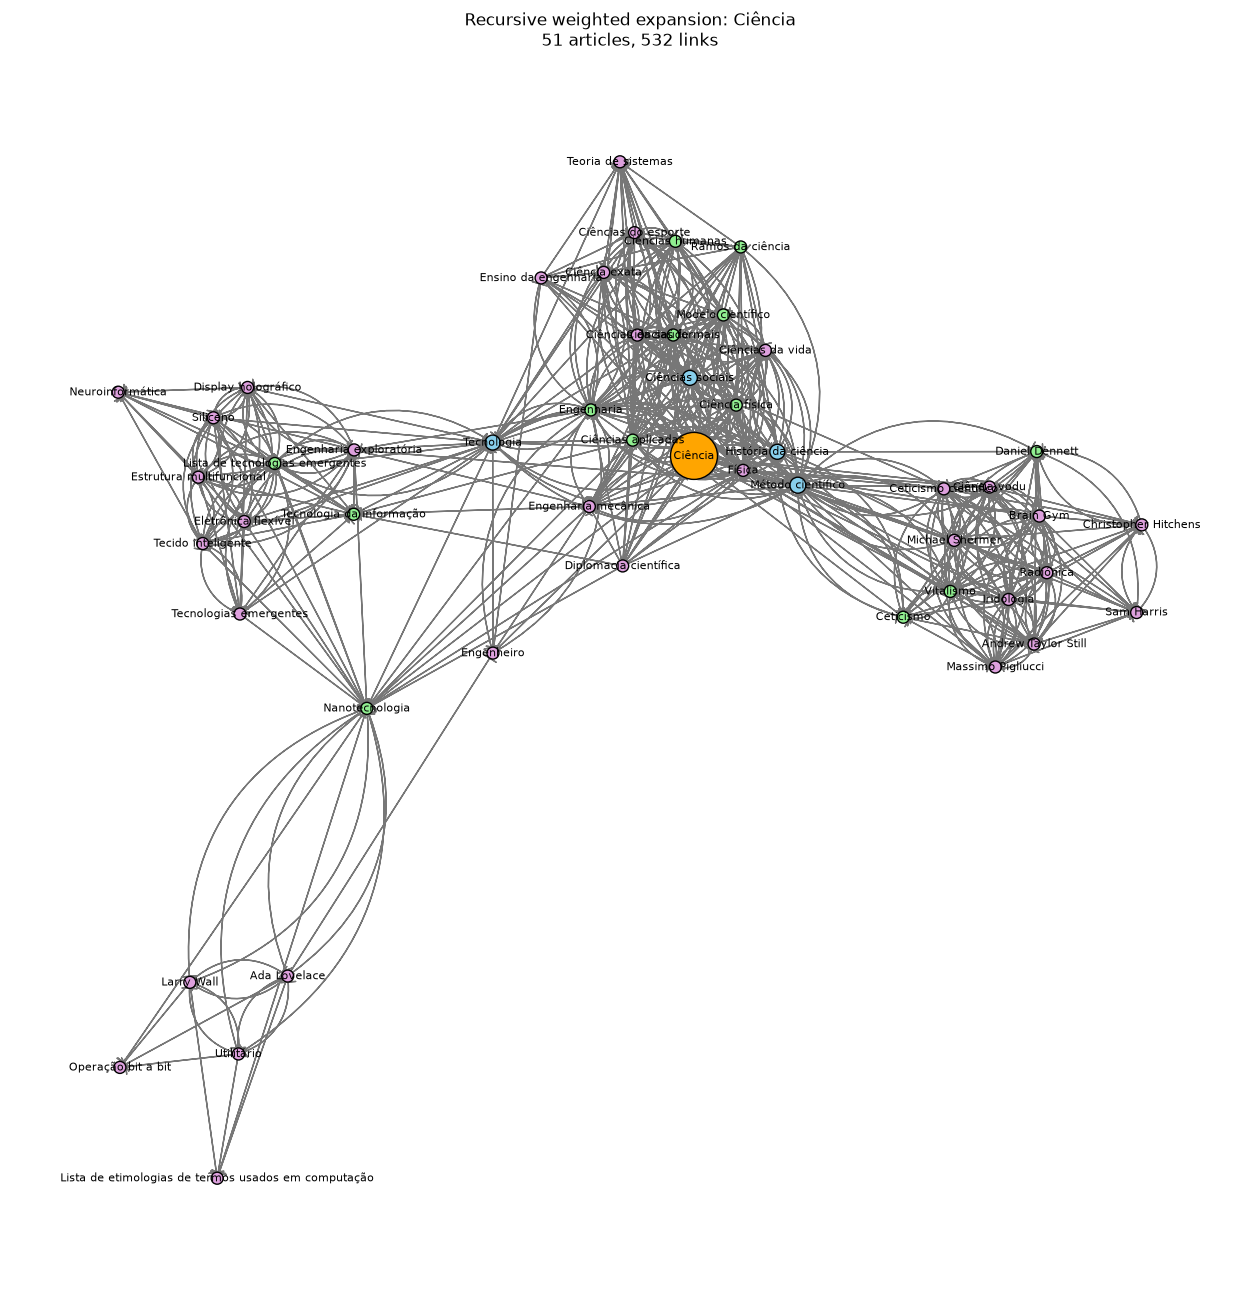


Expansion summary:
Depth 0: 1 articles
Depth 1: 4 articles
Depth 2: 13 articles
Depth 3: 33 articles

Total articles: 51
Total internal links: 532

Discovered articles:
Depth 0 | Score 1.0000 | Ciência
Depth 1 | Score 0.1322 | Método_científico
Depth 1 | Score 0.1052 | História_da_ciência
Depth 1 | Score 0.0939 | Tecnologia
Depth 1 | Score 0.0917 | Ciências_sociais
Depth 2 | Score 0.0279 | Vitalismo
Depth 2 | Score 0.0273 | Daniel_Dennett
Depth 2 | Score 0.0261 | Ceticismo
Depth 2 | Score 0.0178 | Modelo_científico
Depth 2 | Score 0.0177 | Ciência_física
Depth 2 | Score 0.0175 | Ramos_da_ciência
Depth 2 | Score 0.0174 | Ciências_formais
Depth 2 | Score 0.0050 | Engenharia
Depth 2 | Score 0.0050 | Nanotecnologia
Depth 2 | Score 0.0048 | Lista_de_tecnologias_emergentes
Depth 2 | Score 0.0044 | Tecnologia_da_informação
Depth 2 | Score 0.0136 | Ciências_humanas
Depth 2 | Score 0.0119 | Ciências_aplicadas
Depth 3 | Score 0.0104 | Ciência_vodu
Depth 3 | Score 0.0104 | Andrew_Taylor_Still
De

In [8]:

import duckdb
import igraph as ig
import matplotlib.pyplot as plt

# ============================================================
# SETTINGS
# ============================================================

graph_file = "ptwiki_custom-20261101-graph.parquet"
nodes_file = "ptwiki_custom-20261101-nodes.parquet"

starting_article = "Ciência"

max_depth = 3
branch_factor = 5

# Articles that should never enter the expanded graph
excluded_articles = {
    "Pseudociência",
    "Homeopatia",
    "Astrologia",
    "Passe_magnético",
    "Doença_espiritual",
    # Add other unwanted articles here
}

# ============================================================
# SQL: FIND THE TOP WEIGHTED NEIGHBORS OF ONE ARTICLE
# ============================================================

neighbor_query = """
WITH seed_neighbors AS (
    SELECT target_id AS candidate_id
    FROM read_parquet(?)
    WHERE source_id = ?

    UNION

    SELECT source_id AS candidate_id
    FROM read_parquet(?)
    WHERE target_id = ?
),

seed_degree AS (
    SELECT COUNT(*) AS n
    FROM seed_neighbors
),

candidate_neighbors AS (
    SELECT e.source_id AS candidate_id, e.target_id AS neighbor_id
    FROM read_parquet(?) e
    INNER JOIN seed_neighbors s
        ON e.source_id = s.candidate_id

    UNION

    SELECT e.target_id AS candidate_id, e.source_id AS neighbor_id
    FROM read_parquet(?) e
    INNER JOIN seed_neighbors s
        ON e.target_id = s.candidate_id
),

candidate_stats AS (
    SELECT
        candidate_id,
        COUNT(DISTINCT neighbor_id) AS candidate_degree,

        COUNT(DISTINCT CASE
            WHEN neighbor_id IN (
                SELECT candidate_id FROM seed_neighbors
            )
            THEN neighbor_id
        END) AS shared_neighbors

    FROM candidate_neighbors
    GROUP BY candidate_id
)

SELECT
    n.page_id,
    n.page_title,
    s.shared_neighbors,
    s.candidate_degree,

    s.shared_neighbors * 1.0 /
    NULLIF(
        (SELECT n FROM seed_degree)
        + s.candidate_degree
        - s.shared_neighbors,
        0
    ) AS weight

FROM candidate_stats s

JOIN read_parquet(?) n
    ON n.page_id = s.candidate_id

ORDER BY weight DESC, shared_neighbors DESC

LIMIT ?
"""

# ============================================================
# CONNECT TO DUCKDB
# ============================================================

con = duckdb.connect()

# Find starting article
result = con.execute("""
    SELECT page_id, page_title
    FROM read_parquet(?)
    WHERE replace(page_title, '_', ' ') = ?
""", [nodes_file, starting_article]).fetchone()

if result is None:
    con.close()
    raise ValueError(f"Article not found: {starting_article}")

seed_id, seed_title = result

print(f"Starting article: {seed_title}")

# ============================================================
# RECURSIVE EXPANSION
# ============================================================

# Every node stores:
# title, depth, cumulative score, parent article

nodes = {
    seed_id: {
        "title": seed_title,
        "depth": 0,
        "score": 1.0,
        "parent": None
    }
}

frontier = [seed_id]
expanded = set()

for depth in range(1, max_depth + 1):

    next_frontier = []
    queued = set()

    print(f"\nExpanding depth {depth}...")

    for parent_id in frontier:

        if parent_id in expanded:
            continue

        expanded.add(parent_id)

        parent_score = nodes[parent_id]["score"]

        # Get the strongest neighbors of this parent
        results = con.execute(
            neighbor_query,
            [
                graph_file, parent_id,
                graph_file, parent_id,
                graph_file,
                graph_file,
                nodes_file,
                branch_factor
            ]
        ).fetchall()

        for row in results:
            candidate_id = row[0]
            candidate_title = row[1]
            local_weight = float(row[4])

            # Normalize title for comparison
            normalized_title = candidate_title.replace("_", " ").casefold()

            normalized_exclusions = {
                title.replace("_", " ").casefold()
                for title in excluded_articles
            }

            # Skip manually excluded articles
            if normalized_title in normalized_exclusions:
                continue

            # Cumulative score along this path
            cumulative_score = parent_score * local_weight

            # Ignore the original starting article
            if candidate_id == seed_id:
                continue

            # Add new articles, or keep the best path
            if candidate_id not in nodes:

                nodes[candidate_id] = {
                    "title": candidate_title,
                    "depth": depth,
                    "score": cumulative_score,
                    "parent": parent_id
                }

            elif nodes[candidate_id]["depth"] == depth:

                if cumulative_score > nodes[candidate_id]["score"]:
                    nodes[candidate_id]["score"] = cumulative_score
                    nodes[candidate_id]["parent"] = parent_id

            else:
                # Already discovered at an earlier depth
                continue

            # Schedule this article for the next expansion
            if candidate_id not in queued:
                next_frontier.append(candidate_id)
                queued.add(candidate_id)

    frontier = next_frontier

    print(f"Articles discovered so far: {len(nodes)}")

# ============================================================
# RETRIEVE ACTUAL LINKS BETWEEN ALL SELECTED ARTICLES
# ============================================================

selected_ids = list(nodes.keys())

placeholders = ", ".join(["?"] * len(selected_ids))

internal_edges = con.execute(f"""
    SELECT DISTINCT source_id, target_id
    FROM read_parquet(?)
    WHERE source_id IN ({placeholders})
      AND target_id IN ({placeholders})
""", [graph_file] + selected_ids + selected_ids).fetchall()

con.close()

# ============================================================
# BUILD GRAPH
# ============================================================

id_to_index = {
    article_id: index
    for index, article_id in enumerate(selected_ids)
}

g = ig.Graph(directed=True)
g.add_vertices(len(selected_ids))

titles = [
    nodes[article_id]["title"].replace("_", " ")
    for article_id in selected_ids
]

g.vs["name"] = titles

edges = [
    (id_to_index[source], id_to_index[target])
    for source, target in internal_edges
]

g.add_edges(edges)

# ============================================================
# VISUALIZATION
# ============================================================

depths = [
    nodes[article_id]["depth"]
    for article_id in selected_ids
]

scores = [
    nodes[article_id]["score"]
    for article_id in selected_ids
]

# Node sizes represent cumulative scores
sizes = [
    12 + 35 * score
    for score in scores
]

# Color nodes according to expansion depth
depth_colors = {
    0: "orange",
    1: "skyblue",
    2: "lightgreen",
    3: "plum",
    4: "salmon"
}

colors = [
    depth_colors.get(depth, "lightgray")
    for depth in depths
]

fig, ax = plt.subplots(figsize=(16, 16))

ig.plot(
    g,
    target=ax,
    layout=g.layout("fr"),
    vertex_size=sizes,
    vertex_color=colors,
    vertex_label=titles,
    vertex_label_size=8,
    edge_arrow_size=0.5,
    edge_width=1,
    edge_color="#777777",
    margin=70
)

plt.title(
    f"Recursive weighted expansion: {starting_article}\n"
    f"{len(selected_ids)} articles, {len(edges)} links"
)

plt.show()

# ============================================================
# SUMMARY
# ============================================================

print("\nExpansion summary:")

for depth in range(max_depth + 1):
    count = sum(
        1 for article in nodes.values()
        if article["depth"] == depth
    )
    print(f"Depth {depth}: {count} articles")

print(f"\nTotal articles: {len(nodes)}")
print(f"Total internal links: {len(edges)}")

# Show the discovery paths
print("\nDiscovered articles:")

for article_id, article in nodes.items():
    print(
        f"Depth {article['depth']} | "
        f"Score {article['score']:.4f} | "
        f"{article['title']}"
    )
